# XGBoost Baseline — v002 학습 및 검증

## 프로젝트
GEM (Global Export Management)

## 목표
20개국 × 8개 HS6 제품군의 한국 분기별 수출금액(USD·FOB) 예측

## 데이터
- 데이터 버전: v002
- 학습: 2013Q1 ~ 2021Q4
- 검증: 2022Q1 ~ 2025Q4
- 최종 테스트: 2026Q1 ~ 2026Q3 (사용하지 않음)

## 실험 구성
1. XGBoost Baseline — 거시지표 제외
2. XGBoost Baseline — 거시지표 포함

## 전처리
- 결측값 대체
- 범주형 원-핫 인코딩
- 정규화·표준화 미적용
- L1·L2 별도 튜닝 미실시

## 평가 지표
WAPE, MAE, RMSE, sMAPE

In [1]:
from pathlib import Path
import json
import platform

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

print("Python:", platform.python_version())
print("XGBoost:", xgboost.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

Python: 3.12.10
XGBoost: 3.4.1
scikit-learn: 1.9.1
pandas: 3.1.0


In [2]:
# notebooks 폴더에서 실행하는 것을 기준으로 프로젝트 루트 설정
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "shared" / "v002"
OUT = ROOT / "artifacts" / "xgboost" / "v002" / "baseline_notebook"

SEED = 42

MACRO = [
    "gdp_usd",
    "gdp_per_capita_usd",
    "population",
    "inflation_pct",
    "exchange_rate_lcu_per_usd",
    "internet_users_pct"
]

PARAMS = dict(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1
)

print("프로젝트 경로:", ROOT)
print("데이터 경로:", DATA)
print("데이터 폴더 존재:", DATA.exists())

프로젝트 경로: D:\hjs\five-stack
데이터 경로: D:\hjs\five-stack\data\shared\v002
데이터 폴더 존재: True


In [3]:
manifest = json.loads(
    (DATA / "manifest.json").read_text(encoding="utf-8")
)

train = pd.read_parquet(DATA / "train.parquet")
val = pd.read_parquet(DATA / "validation.parquet")

features = manifest["feature_columns"]
target = manifest["feature_contract"]["target"]
categorical = manifest["feature_contract"]["categorical"]

print("데이터 버전:", manifest["dataset_version"])
print("학습 데이터 크기:", train.shape)
print("검증 데이터 크기:", val.shape)
print("전체 입력 변수:", len(features))
print("범주형 변수:", categorical)

display(train.head())

데이터 버전: v002
학습 데이터 크기: (28800, 87)
검증 데이터 크기: (12800, 87)
전체 입력 변수: 57
범주형 변수: ['country_code', 'region', 'hs_code']


,country_code,region,hs_code,target_year,target_quarter_number,horizon_quarters,time_index,export_value_usd_lag1,export_value_usd_lag2,export_value_usd_lag4,...,split,currency,valuation,market_candidate_quarter,market_selection_status,macro_candidate_year,macro_selection_status,macro_candidate_row_exists,historical_release_verified,feature_selection_status
0,AUS,oceania,330300,2013,1,5,0,<NA>,<NA>,<NA>,...,train,USD,FOB,2011Q4,exact_origin_observation_release_unverified,2010,previous_calendar_year_candidate_release_unver...,False,False,calendar_candidates_pending_publication_policy
1,AUS,oceania,330300,2013,1,4,0,<NA>,<NA>,<NA>,...,train,USD,FOB,2012Q1,exact_origin_observation_release_unverified,2011,previous_calendar_year_candidate_release_unver...,False,False,calendar_candidates_pending_publication_policy
2,AUS,oceania,330300,2013,2,5,1,<NA>,<NA>,<NA>,...,train,USD,FOB,2012Q1,exact_origin_observation_release_unverified,2011,previous_calendar_year_candidate_release_unver...,False,False,calendar_candidates_pending_publication_policy
3,AUS,oceania,330300,2013,1,3,0,<NA>,<NA>,<NA>,...,train,USD,FOB,2012Q2,exact_origin_observation_release_unverified,2011,previous_calendar_year_candidate_release_unver...,False,False,calendar_candidates_pending_publication_policy
4,AUS,oceania,330300,2013,2,4,1,<NA>,<NA>,<NA>,...,train,USD,FOB,2012Q2,exact_origin_observation_release_unverified,2011,previous_calendar_year_candidate_release_unver...,False,False,calendar_candidates_pending_publication_policy


In [4]:
# 데이터 버전 확인
assert manifest["dataset_version"] == "v002"

# 학습·검증 기간 확인
print("학습 대상 기간:")
print(train["target_quarter"].min(), "~",
      train["target_quarter"].max())

print("\n검증 대상 기간:")
print(val["target_quarter"].min(), "~",
      val["target_quarter"].max())

# 정답 결측 확인
print("\n학습 정답 결측:", train[target].isna().sum())
print("검증 정답 결측:", val[target].isna().sum())

# 예측 거리 확인
print("\n검증 예측 거리:")
print(sorted(val["horizon_quarters"].dropna().unique()))

# 국가·제품 개수 확인
print("\n국가 수:", train["country_code"].nunique())
print("HS 제품 수:", train["hs_code"].nunique())

학습 대상 기간:
2013Q1 ~ 2021Q4

검증 대상 기간:
2022Q1 ~ 2025Q4

학습 정답 결측: 5510
검증 정답 결측: 1345

검증 예측 거리:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

국가 수: 20
HS 제품 수: 8


In [5]:
# 분기를 시간 순서로 비교하기 위한 함수
def quarter_number(series):
    s = series.astype("string")
    return (
        pd.to_numeric(s.str[:4], errors="raise").astype(int) * 4
        + pd.to_numeric(s.str[-1], errors="raise").astype(int)
        - 1
    )


# 범주형 변수와 숫자형 변수 전처리 + XGBoost 모델 구성
def make_pipeline(columns, categorical):
    numeric = [c for c in columns if c not in categorical]

    transform = ColumnTransformer([
        ("cat", Pipeline([
            ("fill", SimpleImputer(
                strategy="constant",
                fill_value="__MISSING__"
            )),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore"
            )),
        ]), categorical),

        ("num", Pipeline([
            ("fill", SimpleImputer(
                strategy="constant",
                fill_value=0,
                keep_empty_features=True
            )),
        ]), numeric),
    ])

    return Pipeline([
        ("preprocessor", transform),
        ("model", XGBRegressor(**PARAMS))
    ])


# 입력 데이터의 자료형을 맞추는 함수
def inputs(frame, columns, categorical):
    x = frame[columns].copy()

    for c in categorical:
        x[c] = (
            x[c].astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    for c in columns:
        if c not in categorical:
            x[c] = pd.to_numeric(
                x[c], errors="coerce"
            ).astype(float)

    return x


print("XGBoost 전처리 함수 준비 완료!")

XGBoost 전처리 함수 준비 완료!


## XGBoost Baseline — 학습 및 검증

- 모델: XGBoost Regressor
- 학습: 2013Q1 ~ 2021Q4
- 검증: 2022Q1 ~ 2025Q4
- 예측 거리: 1~5분기
- 실험 A: 거시경제 지표 제외
- 실험 B: 거시경제 지표 포함
- StandardScaler: 미적용 (XGBoost 기본 L2 규제는 적용)
- 난수 시드: 42

### 검증 방식
각 예측 기준시점(origin)마다 사용 가능한 학습 정답만 선택합니다.

정답이 결측인 행은 학습과 평가에서 제외합니다.

각 기준시점마다 전처리기와 XGBoost 모델을 새롭게 학습합니다.

2026Q1~Q3 최종 테스트 데이터는 사용하지 않습니다.

In [6]:
# 분기 정보 및 정답 자료형 정리
for frame in (train, val):
    frame["_target_qn"] = quarter_number(frame["target_quarter"])
    frame["_origin_qn"] = quarter_number(frame["origin_quarter"])
    frame[target] = pd.to_numeric(frame[target], errors="coerce")

# 데이터 및 시간 분할 검증
assert manifest["dataset_version"] == "v002"
assert train["target_quarter"].between("2013Q1", "2021Q4").all()
assert val["target_quarter"].between("2022Q1", "2025Q4").all()
assert (val["_origin_qn"] < val["_target_qn"]).all()

assert not set(features) & set(
    manifest["feature_contract"]["forbidden_feature_columns"]
)

# 거시지표 제외 / 포함 구성
configs = {
    "no_macro": [
        c for c in features
        if c not in MACRO
        and c not in [m + "_missing" for m in MACRO]
    ],
    "with_macro": features
}

all_predictions = []

# 두 가지 모델 구성 학습
for name, cols in configs.items():

    print(f"\n===== {name} 학습 시작 =====")

    origins = sorted(
        val["origin_quarter"].dropna().unique(),
        key=lambda q: int(q[:4]) * 4 + int(q[-1])
    )

    for origin in origins:

        origin_qn = int(
            quarter_number(pd.Series([origin])).iloc[0]
        )

        # 기준시점까지의 학습 정답만 사용
        fit = train.loc[
            (train["_target_qn"] <= origin_qn)
            & train[target].notna()
            & train["target_available"].fillna(False)
        ].copy()

        # 검증 정답 결측 제외
        score = val.loc[
            (val["origin_quarter"] == origin)
            & val[target].notna()
            & val["target_available"].fillna(False)
        ].copy()

        if fit.empty or score.empty:
            continue

        # 매 기준시점마다 새 모델 생성
        pipeline = make_pipeline(cols, categorical)

        # 학습
        pipeline.fit(
            inputs(fit, cols, categorical),
            fit[target].astype(float).to_numpy()
        )

        # 예측 (음수 수출금액 방지)
        pred = np.maximum(
            pipeline.predict(inputs(score, cols, categorical)),
            0
        )

        # 예측 결과 저장
        result = score[
            [
                "country_code",
                "hs_code",
                "origin_quarter",
                "target_quarter",
                "horizon_quarters"
            ]
        ].copy()

        result["actual_usd"] = score[target].to_numpy(dtype=float)
        result["predicted_usd"] = pred
        result["model_variant"] = name
        result["fit_rows"] = len(fit)

        all_predictions.append(result)

        print(
            f"{origin}: 학습 {len(fit)}행 / "
            f"검증 {len(score)}행"
        )

# 전체 검증 예측 결과
if not all_predictions:
    raise RuntimeError("검증 예측 결과가 없습니다.")

predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

print("\n===== XGBoost 학습 및 검증 완료 =====")
print("전체 예측 결과:", len(predictions), "행")

display(predictions.head())


===== no_macro 학습 시작 =====
2020Q4: 학습 20565행 / 검증 137행
2021Q1: 학습 21225행 / 검증 284행
2021Q2: 학습 21910행 / 검증 425행
2021Q3: 학습 22605행 / 검증 565행
2021Q4: 학습 23290행 / 검증 703행
2022Q1: 학습 23290행 / 검증 706행
2022Q2: 학습 23290행 / 검증 704행
2022Q3: 학습 23290행 / 검증 703행
2022Q4: 학습 23290행 / 검증 705행
2023Q1: 학습 23290행 / 검증 715행
2023Q2: 학습 23290행 / 검증 718행
2023Q3: 학습 23290행 / 검증 719행
2023Q4: 학습 23290행 / 검증 723행
2024Q1: 학습 23290행 / 검증 727행
2024Q2: 학습 23290행 / 검증 728행
2024Q3: 학습 23290행 / 검증 730행
2024Q4: 학습 23290행 / 검증 584행
2025Q1: 학습 23290행 / 검증 440행
2025Q2: 학습 23290행 / 검증 294행
2025Q3: 학습 23290행 / 검증 145행

===== with_macro 학습 시작 =====
2020Q4: 학습 20565행 / 검증 137행
2021Q1: 학습 21225행 / 검증 284행
2021Q2: 학습 21910행 / 검증 425행
2021Q3: 학습 22605행 / 검증 565행
2021Q4: 학습 23290행 / 검증 703행
2022Q1: 학습 23290행 / 검증 706행
2022Q2: 학습 23290행 / 검증 704행
2022Q3: 학습 23290행 / 검증 703행
2022Q4: 학습 23290행 / 검증 705행
2023Q1: 학습 23290행 / 검증 715행
2023Q2: 학습 23290행 / 검증 718행
2023Q3: 학습 23290행 / 검증 719행
2023Q4: 학습 23290행 / 검증 723행
2024Q1: 학습 23290행 

,country_code,hs_code,origin_quarter,target_quarter,horizon_quarters,actual_usd,predicted_usd,model_variant,fit_rows
0,AUS,330300,2020Q4,2022Q1,5,841.0,0.000000e+00,no_macro,20565
1,AUS,330410,2020Q4,2022Q1,5,298367.0,1.556353e+05,no_macro,20565
2,AUS,330420,2020Q4,2022Q1,5,839385.0,1.688221e+05,no_macro,20565
3,AUS,330491,2020Q4,2022Q1,5,35335.0,3.875414e+04,no_macro,20565
4,AUS,330499,2020Q4,2022Q1,5,8055143.0,9.647197e+06,no_macro,20565


In [7]:
# XGBoost 평가 지표 계산 함수
def metrics(frame):
    y = frame["actual_usd"].to_numpy(dtype=float)
    p = frame["predicted_usd"].to_numpy(dtype=float)

    error = np.abs(y - p)
    denominator = np.abs(y).sum()
    sm_denominator = np.abs(y) + np.abs(p)

    return pd.Series({
        "rows": len(frame),
        "WAPE_pct": (
            100 * error.sum() / denominator
            if denominator else np.nan
        ),
        "MAE_usd": error.mean(),
        "RMSE_usd": np.sqrt(np.mean((y - p) ** 2)),
        "sMAPE_pct": 100 * np.mean(
            np.divide(
                2 * error,
                sm_denominator,
                out=np.zeros_like(error),
                where=sm_denominator != 0
            )
        )
    })


# 전체 / 예측 거리별 / 국가별 / 제품별 평가
grouped = []

for group_by in [
    ["model_variant"],
    ["model_variant", "horizon_quarters"],
    ["model_variant", "country_code"],
    ["model_variant", "hs_code"]
]:
    for key, subset in predictions.groupby(group_by, dropna=False):
        key = key if isinstance(key, tuple) else (key,)

        row = dict(zip(group_by, key))
        row.update(metrics(subset).to_dict())
        row["grouping"] = "+".join(group_by)

        grouped.append(row)

metrics_df = pd.DataFrame(grouped)

# 전체 모델 성능 비교
overall = metrics_df[
    metrics_df["grouping"] == "model_variant"
].copy()

print("===== XGBoost 전체 성능 비교 =====")
display(overall[
    ["model_variant", "rows", "WAPE_pct",
     "MAE_usd", "RMSE_usd", "sMAPE_pct"]
].round(4))

# 예측 거리별 성능 비교
print("===== 예측 거리별 WAPE =====")
horizon_result = metrics_df[
    metrics_df["grouping"] == "model_variant+horizon_quarters"
]

display(
    horizon_result.pivot(
        index="horizon_quarters",
        columns="model_variant",
        values="WAPE_pct"
    ).round(2)
)

===== XGBoost 전체 성능 비교 =====


,model_variant,rows,WAPE_pct,MAE_usd,RMSE_usd,sMAPE_pct
0,no_macro,11455.0,53.5164,5.769309e+06,4.480756e+07,74.0088
1,with_macro,11455.0,55.7550,6.010643e+06,4.482966e+07,79.3880


===== 예측 거리별 WAPE =====


model_variant,no_macro,with_macro
horizon_quarters,,
1.0,54.33,56.72
2.0,53.85,55.97
3.0,52.98,55.34
4.0,52.96,55.20
5.0,53.46,55.53


In [8]:
# 국가별 XGBoost WAPE 비교
country_result = metrics_df[
    metrics_df["grouping"] == "model_variant+country_code"
]

country_wape = country_result.pivot(
    index="country_code",
    columns="model_variant",
    values="WAPE_pct"
)

print("===== 국가별 WAPE (높은 순서) =====")
display(
    country_wape.sort_values(
        "no_macro",
        ascending=False
    ).round(2)
)


# HS6 제품별 XGBoost WAPE 비교
product_result = metrics_df[
    metrics_df["grouping"] == "model_variant+hs_code"
]

product_wape = product_result.pivot(
    index="hs_code",
    columns="model_variant",
    values="WAPE_pct"
)

print("===== 제품별 WAPE (높은 순서) =====")
display(
    product_wape.sort_values(
        "no_macro",
        ascending=False
    ).round(2)
)

===== 국가별 WAPE (높은 순서) =====


model_variant,no_macro,with_macro
country_code,,
GTM,167.71,105.13
CHN,79.79,80.49
MAR,62.18,73.92
USA,55.47,55.77
ZAF,41.94,45.56
BRA,41.23,46.30
IDN,34.86,30.77
NZL,33.24,33.93
ITA,32.90,34.97


===== 제품별 WAPE (높은 순서) =====


model_variant,no_macro,with_macro
hs_code,,
330300,176.39,262.66
330510,76.15,71.80
330499,55.77,57.88
330491,52.62,52.81
340130,46.08,48.29
330410,36.01,37.96
330590,31.69,31.84
330420,23.67,23.42


## XGBoost Baseline — v002 검증 결과 해석

아래 결과는 **이 노트북을 v002 데이터로 실행한 뒤** 산출한 WAPE를 기준으로 해석합니다.
과거 v001 실행값을 v002 실험 결과로 표시하지 않습니다.

- 거시지표 포함/제외의 차이는 다음 셀에서 출력되는 전체 WAPE로 비교합니다.
- XGBoost는 트리 기반 모델이므로 Baseline에는 StandardScaler를 적용하지 않았습니다.
- 검증 정답은 학습에 사용하지 않고, 학습 데이터에 있는 시점별 정답만 사용했습니다. 따라서 완전한 확장형 학습(expanding window)과는 다릅니다.


In [9]:
# v002에서 실제 계산한 결과만 요약
report = overall.set_index("model_variant")["WAPE_pct"]
for name in ("no_macro", "with_macro"):
    if name in report.index:
        print(f"{name}: WAPE {report[name]:.4f}%")
if {"no_macro", "with_macro"}.issubset(report.index):
    print(f"두 모델 WAPE 차이: {abs(report['no_macro'] - report['with_macro']):.4f}%p")


no_macro: WAPE 53.5164%
with_macro: WAPE 55.7550%
두 모델 WAPE 차이: 2.2386%p


In [10]:
# 결과 저장 폴더 생성
OUT.mkdir(parents=True, exist_ok=True)

# 1. 검증 예측 결과 저장
predictions.to_csv(
    OUT / "validation_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. 평가 지표 저장
metrics_df.to_csv(
    OUT / "metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

# 3. 두 가지 XGBoost 최종 학습 모델 저장
for name, cols in configs.items():

    full_fit = train.loc[
        train[target].notna()
        & train["target_available"].fillna(False)
    ].copy()

    final_pipeline = make_pipeline(cols, categorical)

    final_pipeline.fit(
        inputs(full_fit, cols, categorical),
        full_fit[target].astype(float).to_numpy()
    )

    joblib.dump(
        {
            "pipeline": final_pipeline,
            "feature_columns": cols,
            "categorical_columns": categorical,
            "dataset_version": "v002",
            "trained_through_target_quarter": "2021Q4"
        },
        OUT / f"{name}_train_only.joblib"
    )

    print(f"{name} 모델 저장 완료")

# 4. 실험 설정 기록
config = {
    "dataset_version": "v002",
    "seed": SEED,
    "parameters": PARAMS,
    "feature_columns_by_variant": configs,
    "categorical_columns": categorical,
    "train_target_period": manifest["train_period"],
    "validation_target_period": manifest["validation_period"],
    "validation_method": "expanding_origin_train_only_labels",
    "metric_priority": "WAPE_pct",
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "limitations": manifest["availability_limitation"],
    "note": (
        "Validation labels are never used for fitting; "
        "validation is calendar-aligned, not vintage-verified."
    )
}

(OUT / "experiment_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("\n===== 저장 완료 =====")
for file in sorted(OUT.iterdir()):
    print(file.name)

no_macro 모델 저장 완료
with_macro 모델 저장 완료

===== 저장 완료 =====
experiment_config.json
metrics.csv
no_macro_train_only.joblib
validation_predictions.csv
with_macro_train_only.joblib


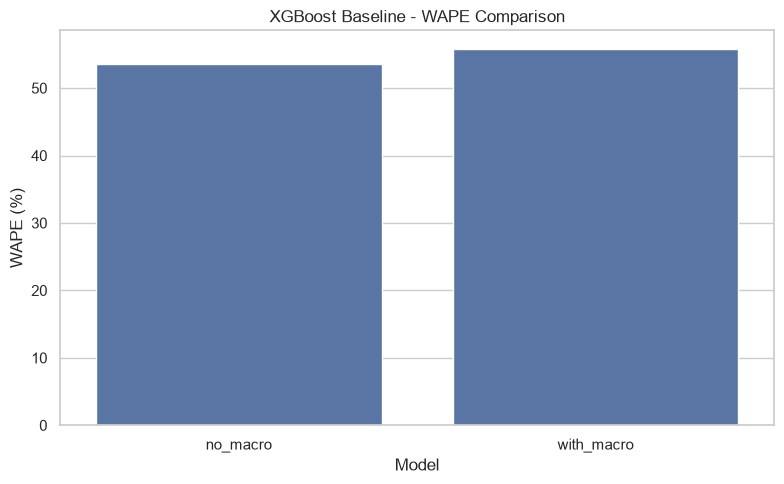

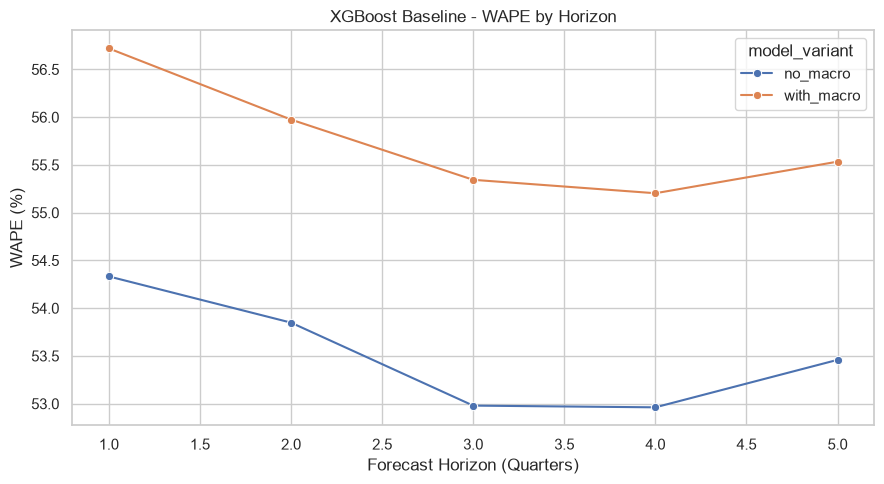

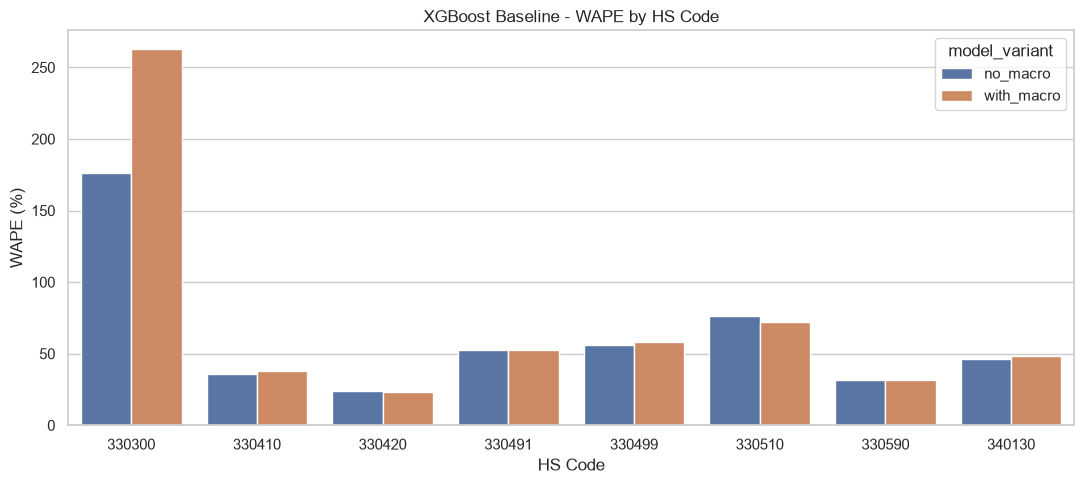

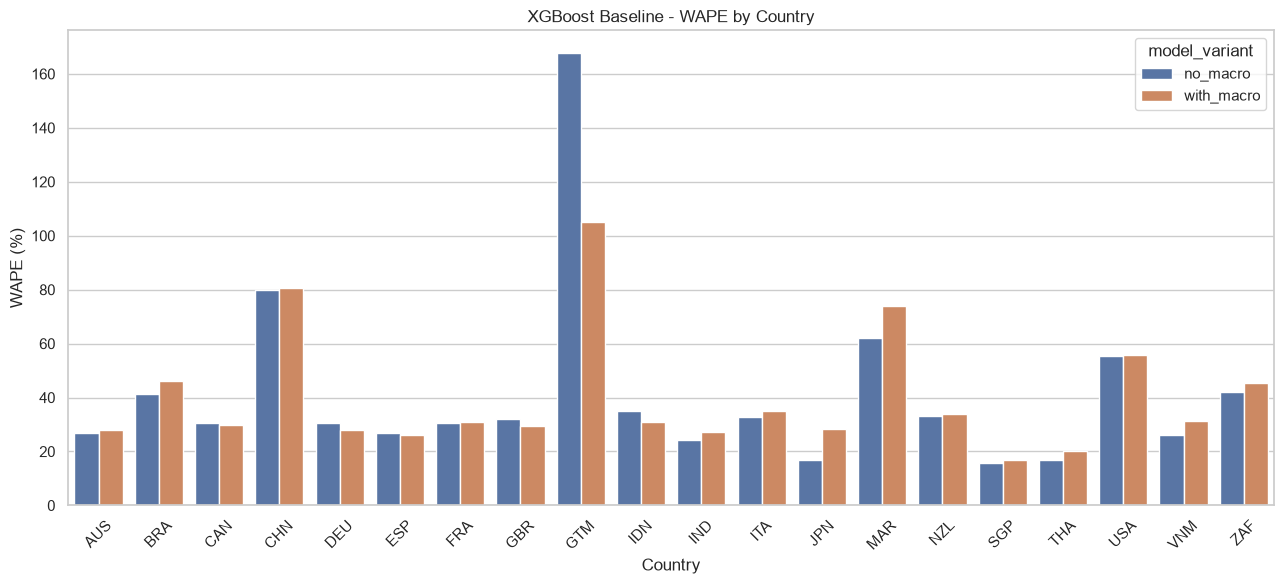

Baseline 그래프 4개 저장 완료!
저장 위치: D:\hjs\five-stack\artifacts\xgboost\v002\baseline_notebook\graphs


In [11]:

# STEP 13: XGBoost Baseline 그래프 4개
# 기존 Baseline 변수: metrics_df, predictions, OUT

import matplotlib.pyplot as plt
import seaborn as sns

GRAPH_DIR = OUT / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

# 전체 성능만 추출
overall_graph = metrics_df[
    metrics_df["grouping"] == "model_variant"
].copy()

# 예측 기간별 성능
horizon_graph = metrics_df[
    metrics_df["grouping"] == "model_variant+horizon_quarters"
].copy()

# 제품별 성능
product_graph = metrics_df[
    metrics_df["grouping"] == "model_variant+hs_code"
].copy()

# 국가별 성능
country_graph = metrics_df[
    metrics_df["grouping"] == "model_variant+country_code"
].copy()


# 1. 거시지표 포함/제외 WAPE 비교
plt.figure(figsize=(8, 5))
sns.barplot(
    data=overall_graph,
    x="model_variant",
    y="WAPE_pct"
)
plt.title("XGBoost Baseline - WAPE Comparison")
plt.xlabel("Model")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "01_wape_comparison.png", dpi=150)
plt.show()


# 2. 예측 기간별 WAPE
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=horizon_graph,
    x="horizon_quarters",
    y="WAPE_pct",
    hue="model_variant",
    marker="o"
)
plt.title("XGBoost Baseline - WAPE by Horizon")
plt.xlabel("Forecast Horizon (Quarters)")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "02_horizon_wape.png", dpi=150)
plt.show()


# 3. 제품별 WAPE
plt.figure(figsize=(11, 5))
sns.barplot(
    data=product_graph,
    x="hs_code",
    y="WAPE_pct",
    hue="model_variant"
)
plt.title("XGBoost Baseline - WAPE by HS Code")
plt.xlabel("HS Code")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "03_product_wape.png", dpi=150)
plt.show()


# 4. 국가별 WAPE
plt.figure(figsize=(13, 6))
sns.barplot(
    data=country_graph,
    x="country_code",
    y="WAPE_pct",
    hue="model_variant"
)
plt.title("XGBoost Baseline - WAPE by Country")
plt.xlabel("Country")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "04_country_wape.png", dpi=150)
plt.show()

print("Baseline 그래프 4개 저장 완료!")
print("저장 위치:", GRAPH_DIR)
